# Online Gaming Player Engagement Prediction (Decision Tree Classifier)

**Goal:** Predict **EngagementLevel** (`High`, `Medium`, `Low`) using player demographics + gameplay behavior metrics.

This notebook follows a full **end-to-end ML workflow**:
- Problem understanding
- Data loading + quality checks
- EDA (univariate, bivariate, multivariate)
- Feature engineering + preprocessing
- Baseline Decision Tree
- Evaluation (confusion matrix, accuracy, classification report)
- Hyperparameter tuning
- Tree pruning (cost-complexity pruning)
- Model comparison + final model selection
- Optional: clean **sklearn Pipeline** for production-style workflow


## 1) Problem Statement

Online games want to **retain players** and keep them engaged. If we can predict a player's engagement level early, we can:

- Identify players at risk of dropping engagement (e.g., `Low`)
- Trigger personalized offers / onboarding / difficulty adjustments
- Improve game design by understanding key drivers of engagement

**ML Task:** Multiclass classification
- **Input (X):** demographics + gameplay metrics
- **Target (y):** `EngagementLevel` ∈ {`High`, `Medium`, `Low`}

**Success Criteria (typical):**
- Good overall accuracy
- Good balance across classes (macro-F1)
- Interpretable drivers (feature importance + readable tree)


## 2) Dataset Overview

### Columns in the dataset
- **PlayerID**: Unique identifier (not useful for prediction → we will drop it)
- **Age**
- **Gender**
- **Location**
- **GameGenre**
- **PlayTimeHours**: average hours per session
- **InGamePurchases**: 0/1
- **GameDifficulty**: Easy / Medium / Hard
- **SessionsPerWeek**
- **AvgSessionDurationMinutes**
- **PlayerLevel**
- **AchievementsUnlocked**
- **EngagementLevel (Target)**: High / Medium / Low

### What we will do
- Explore how engagement varies with playtime, sessions, purchases, difficulty, etc.
- Encode categorical variables
- Train decision tree models and interpret them


In [1]:
# 3) Imports and Settings

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

import joblib

# Plot settings
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.grid'] = True
sns.set_theme(style='whitegrid')


In [3]:
# 4) Load the Dataset

DATA_PATH = r'C:\Users\nazmi\Downloads\online_gaming_behavior_dataset.csv'

df = pd.read_csv(DATA_PATH)

df.head()


,PlayerID,Age,Gender,Location,GameGenre,PlayTimeHours,InGamePurchases,GameDifficulty,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked,EngagementLevel
0,9000,43,Male,Other,Strategy,16.271119,0,Medium,6,108,79,25,Medium
1,9001,29,Female,USA,Strategy,5.525961,0,Medium,5,144,11,10,Medium
2,9002,22,Female,USA,Sports,8.223755,0,Easy,16,142,35,41,High
3,9003,35,Male,USA,Action,5.265351,1,Easy,9,85,57,47,Medium
4,9004,33,Male,Europe,Action,15.531945,0,Medium,2,131,95,37,Medium


In [4]:
# Basic shape and column names

print('Shape:', df.shape)
print('\nColumns:')
print(df.columns.tolist())


Shape: (40034, 13)

Columns:
['PlayerID', 'Age', 'Gender', 'Location', 'GameGenre', 'PlayTimeHours', 'InGamePurchases', 'GameDifficulty', 'SessionsPerWeek', 'AvgSessionDurationMinutes', 'PlayerLevel', 'AchievementsUnlocked', 'EngagementLevel']


In [5]:
# Quick dataset summary

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40034 entries, 0 to 40033
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   PlayerID                   40034 non-null  int64  
 1   Age                        40034 non-null  int64  
 2   Gender                     40034 non-null  object 
 3   Location                   40034 non-null  object 
 4   GameGenre                  40034 non-null  object 
 5   PlayTimeHours              40034 non-null  float64
 6   InGamePurchases            40034 non-null  int64  
 7   GameDifficulty             40034 non-null  object 
 8   SessionsPerWeek            40034 non-null  int64  
 9   AvgSessionDurationMinutes  40034 non-null  int64  
 10  PlayerLevel                40034 non-null  int64  
 11  AchievementsUnlocked       40034 non-null  int64  
 12  EngagementLevel            40034 non-null  object 
dtypes: float64(1), int64(7), object(5)
memory usag

In [6]:
# Numeric summary

df.describe()


,PlayerID,Age,PlayTimeHours,InGamePurchases,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked
count,40034.000000,40034.000000,40034.000000,40034.000000,40034.000000,40034.000000,40034.000000,40034.000000
mean,29016.500000,31.992531,12.024365,0.200854,9.471774,94.792252,49.655568,24.526477
std,11556.964675,10.043227,6.914638,0.400644,5.763667,49.011375,28.588379,14.430726
min,9000.000000,15.000000,0.000115,0.000000,0.000000,10.000000,1.000000,0.000000
25%,19008.250000,23.000000,6.067501,0.000000,4.000000,52.000000,25.000000,12.000000
50%,29016.500000,32.000000,12.008002,0.000000,9.000000,95.000000,49.000000,25.000000
75%,39024.750000,41.000000,17.963831,0.000000,14.000000,137.000000,74.000000,37.000000
max,49033.000000,49.000000,23.999592,1.000000,19.000000,179.000000,99.000000,49.000000


In [7]:
# Target distribution

df['EngagementLevel'].value_counts()


EngagementLevel
Medium    19374
High      10336
Low       10324
Name: count, dtype: int64

### Observation

- Check if the target classes are balanced. If one class dominates, accuracy alone can be misleading.
- We'll use **confusion matrix** + **classification report** (precision/recall/F1) to understand performance per class.


In [8]:
# 5) Data Quality Checks

# Missing values
missing = df.isna().sum().sort_values(ascending=False)
print('Missing values per column (top):')
print(missing[missing > 0])

# Duplicate rows
print('\nDuplicate rows:', df.duplicated().sum())


Missing values per column (top):
Series([], dtype: int64)

Duplicate rows: 0


## 6) Exploratory Data Analysis (EDA)

We will do:
- **Univariate analysis**: distribution of each feature
- **Bivariate analysis**: feature vs target
- **Multivariate analysis**: relationships among multiple numeric features

> Tip: In a real notebook, you might not plot every single column if the dataset is huge. Here we keep it structured and classroom-friendly.


### 6.1 Univariate Analysis (Numeric Features)
We'll look at distributions using histograms.

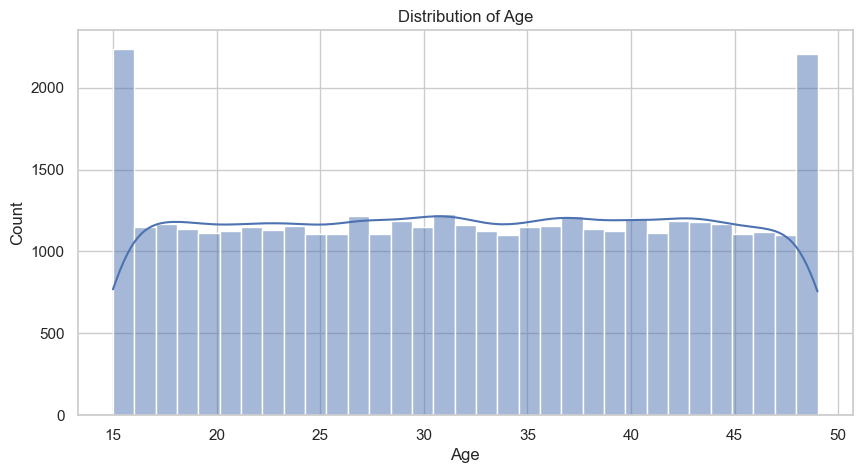

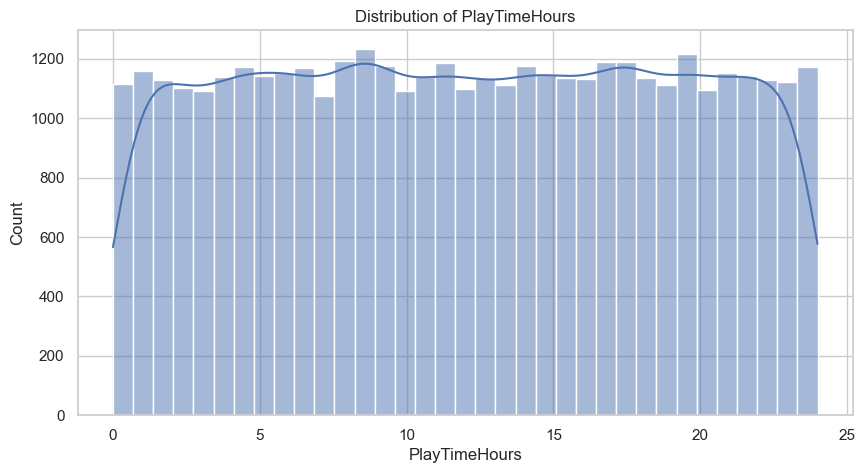

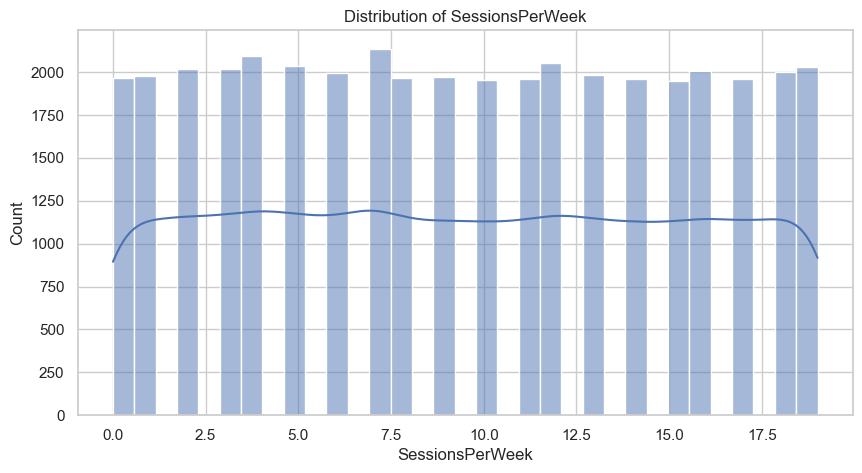

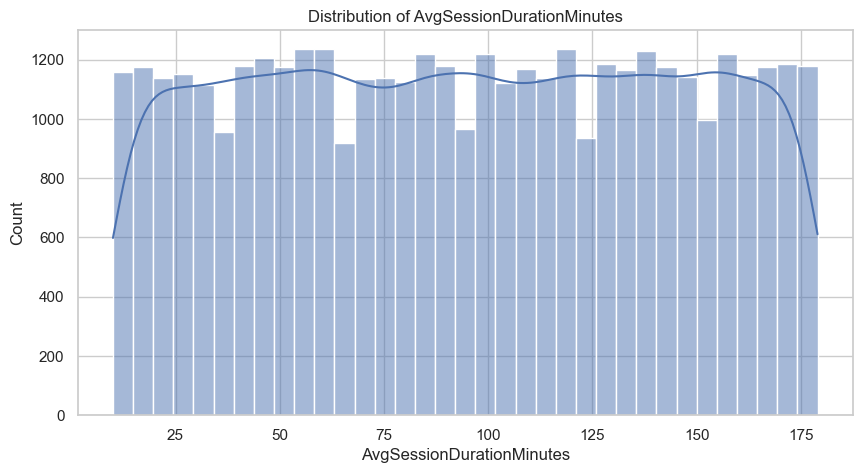

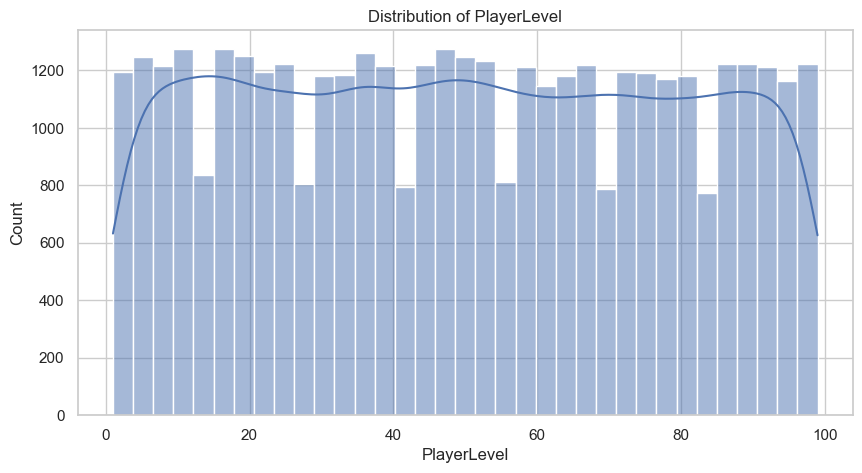

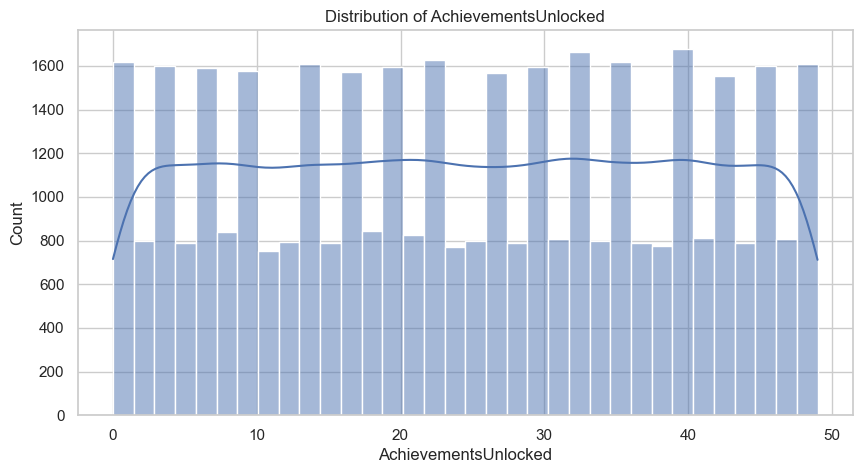

In [9]:
numeric_cols = [
    'Age', 'PlayTimeHours', 'SessionsPerWeek', 'AvgSessionDurationMinutes',
    'PlayerLevel', 'AchievementsUnlocked'
]

for col in numeric_cols:
    plt.figure()
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.show()


### 6.2 Univariate Analysis (Categorical Features)
We'll look at category counts.

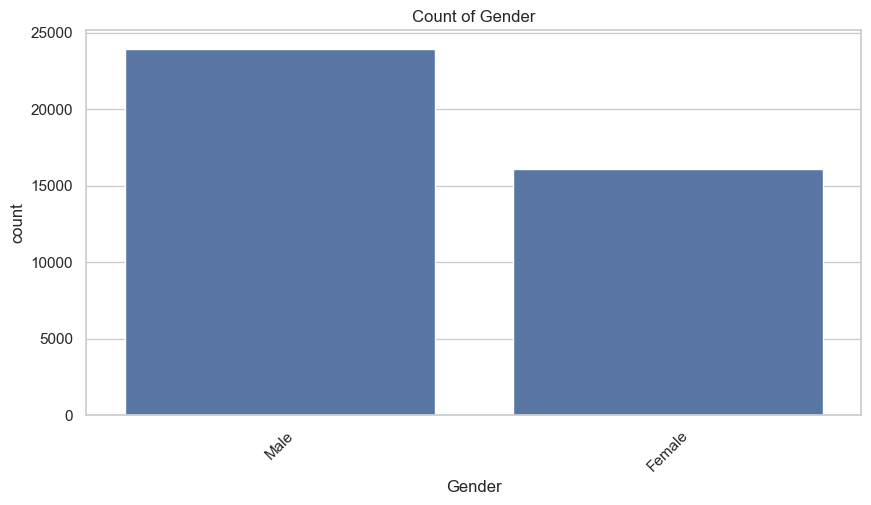

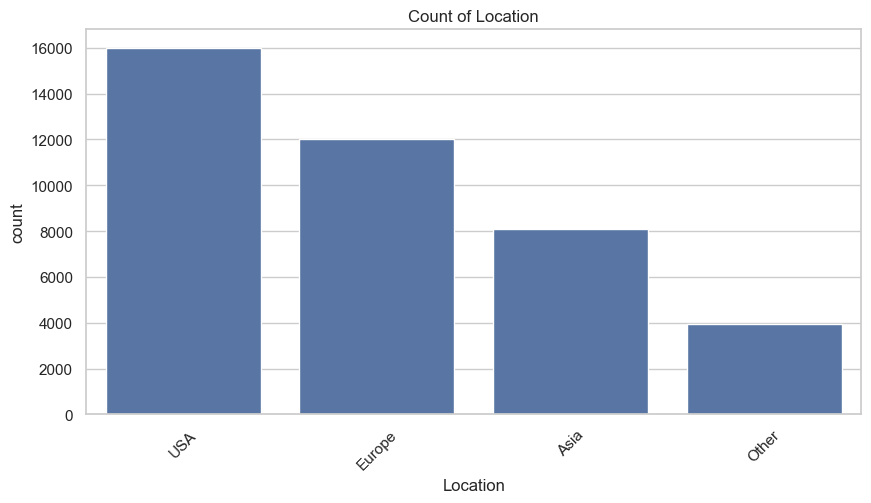

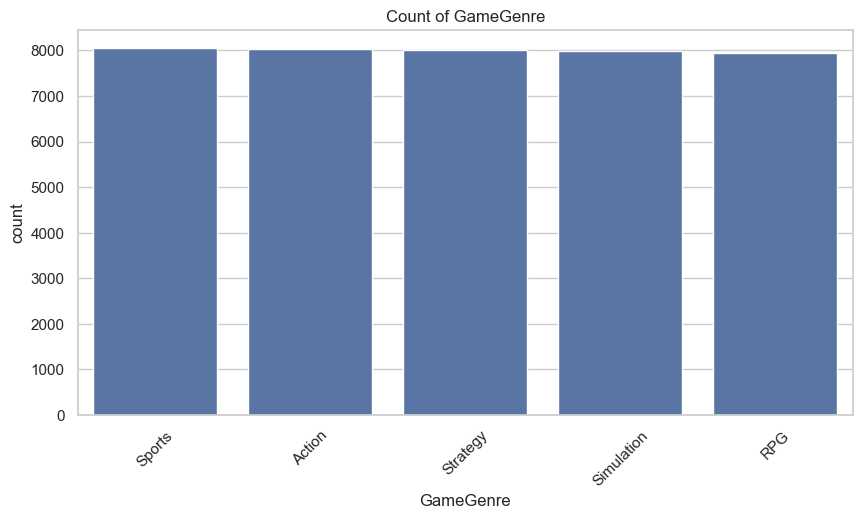

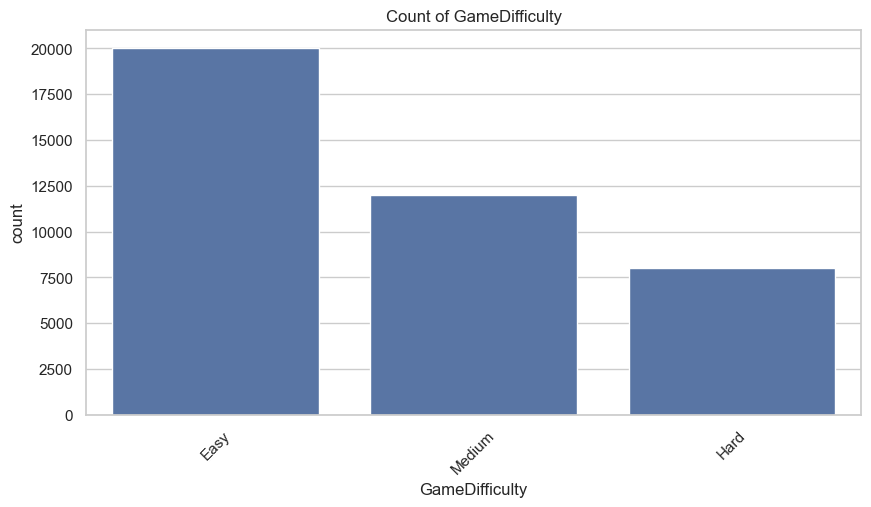

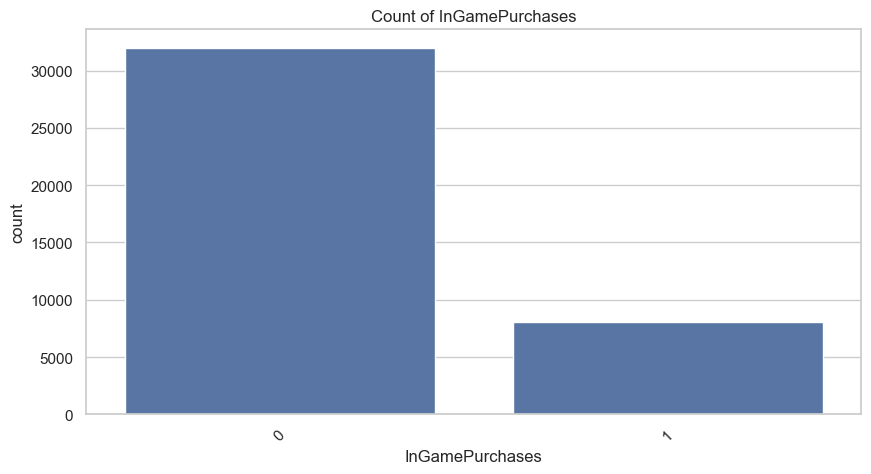

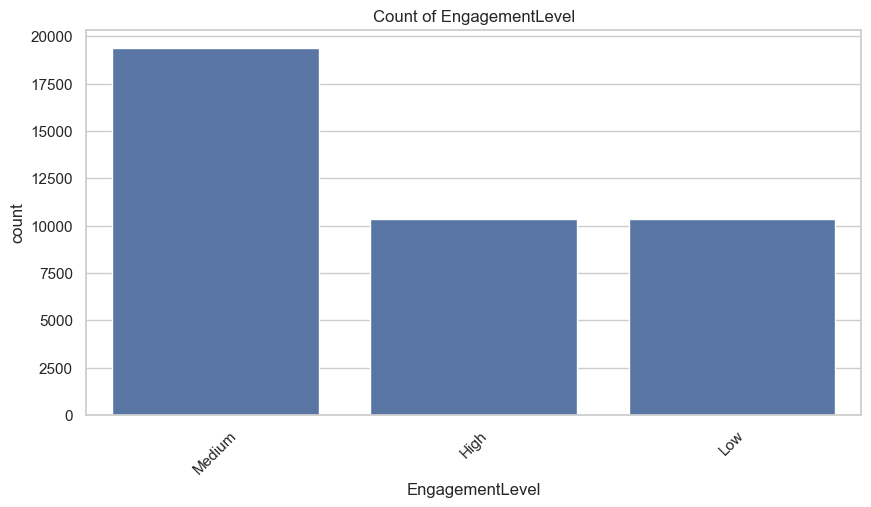

In [10]:
cat_cols = ['Gender', 'Location', 'GameGenre', 'GameDifficulty', 'InGamePurchases', 'EngagementLevel']

for col in cat_cols:
    plt.figure()
    sns.countplot(data=df, x=col, order=df[col].value_counts().index)
    plt.title(f'Count of {col}')
    plt.xticks(rotation=45)
    plt.show()


### 6.3 Bivariate Analysis (Feature vs EngagementLevel)

For numeric features we use **boxplots**. This helps compare distributions across engagement classes.


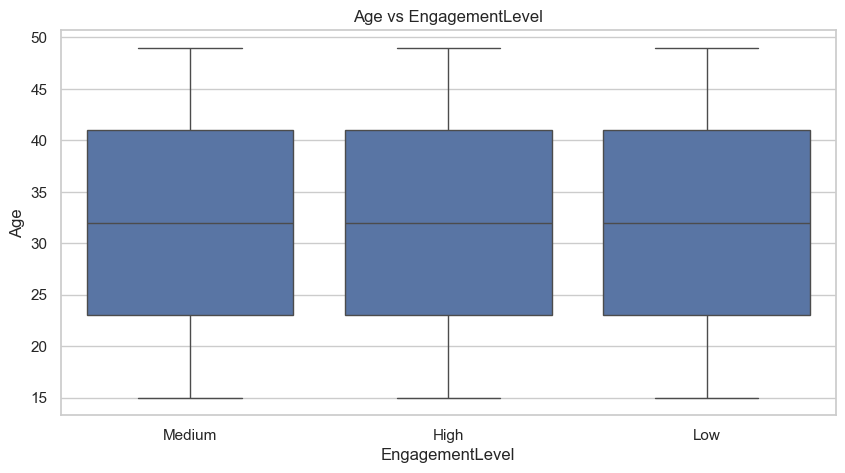

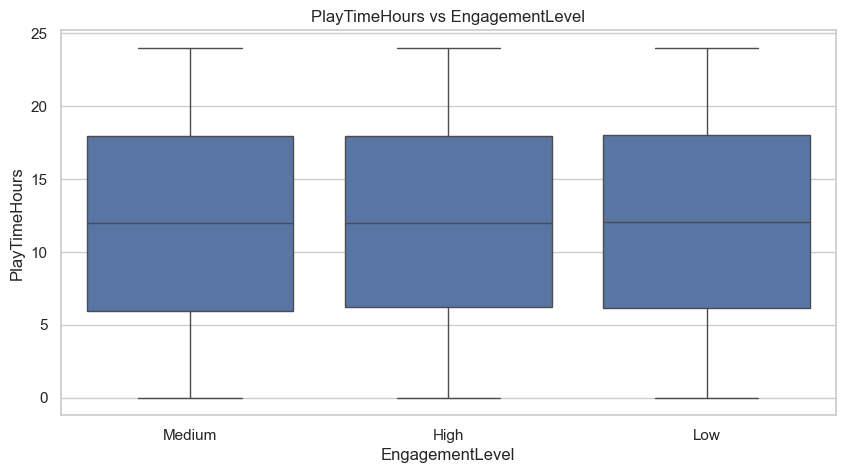

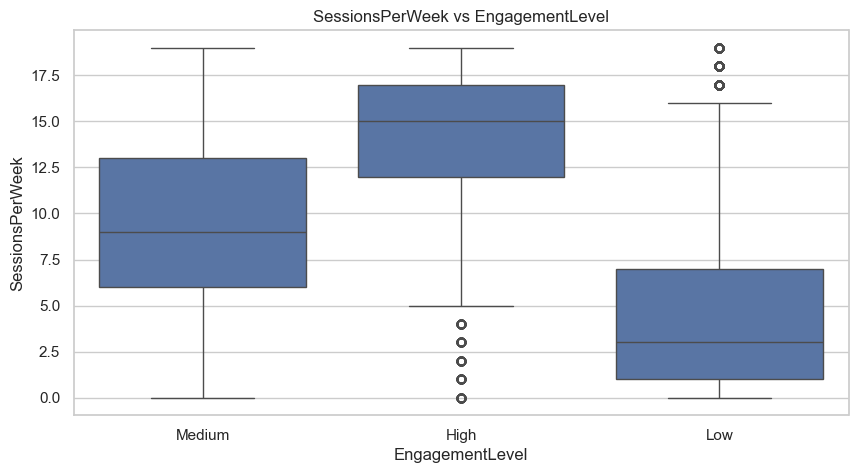

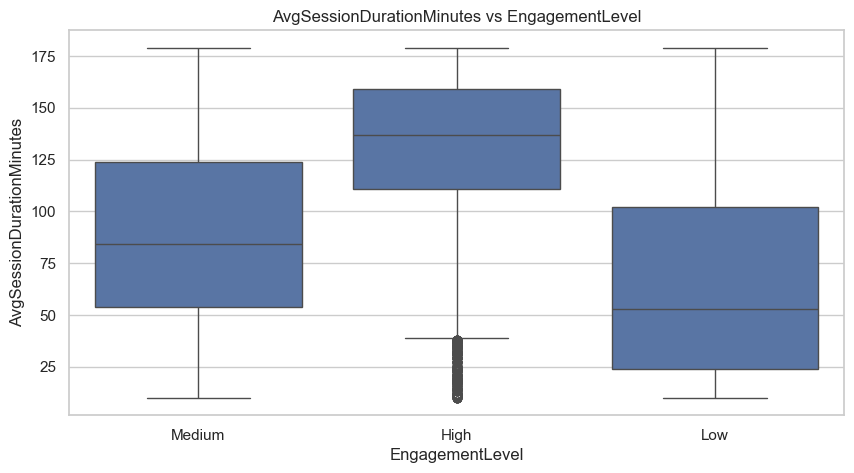

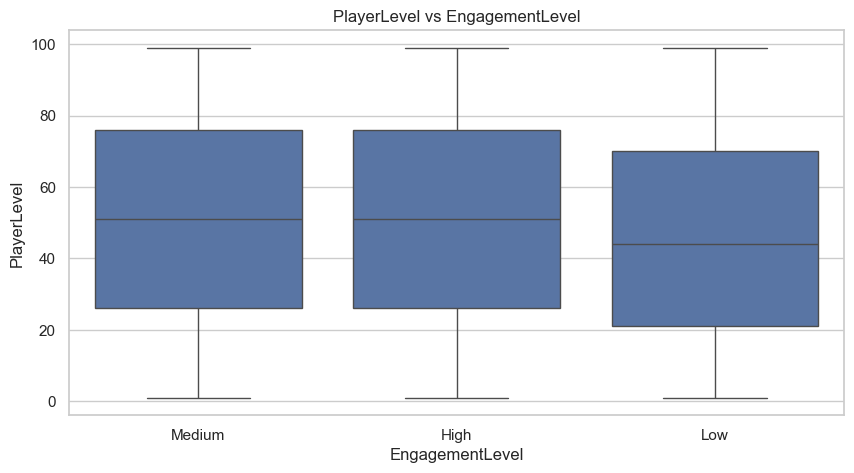

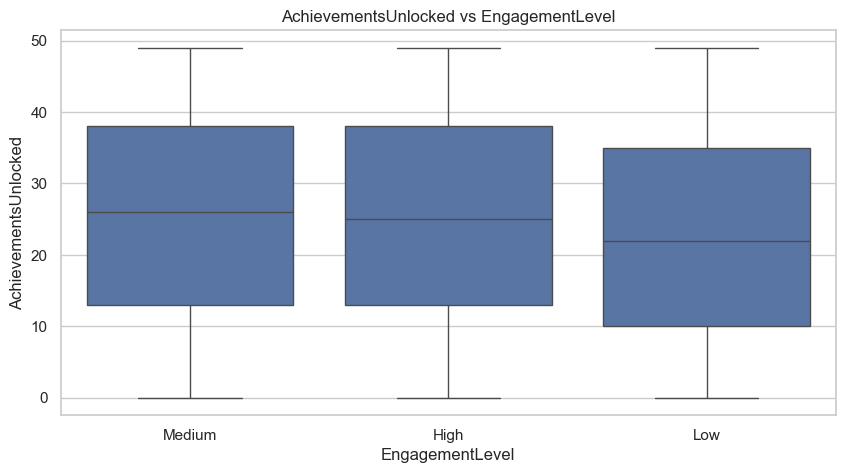

In [11]:
for col in numeric_cols:
    plt.figure()
    sns.boxplot(data=df, x='EngagementLevel', y=col)
    plt.title(f'{col} vs EngagementLevel')
    plt.show()


For categorical features we use **countplots split by EngagementLevel**.

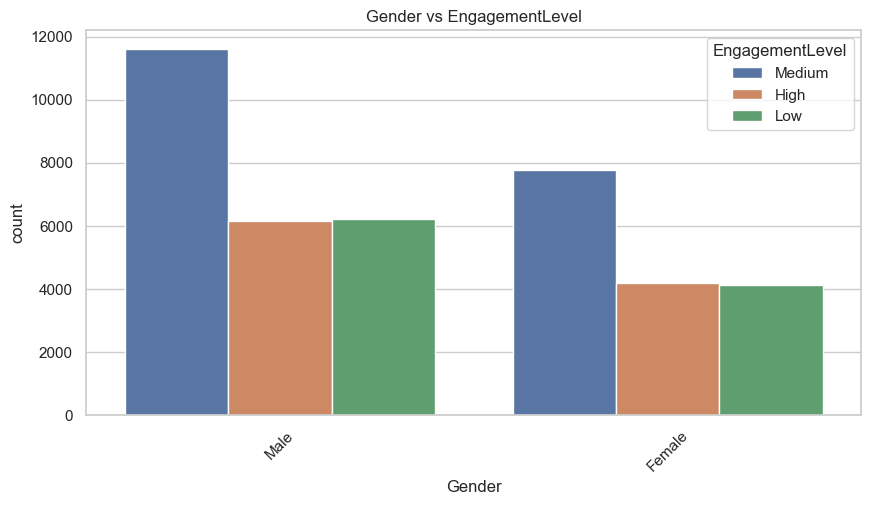

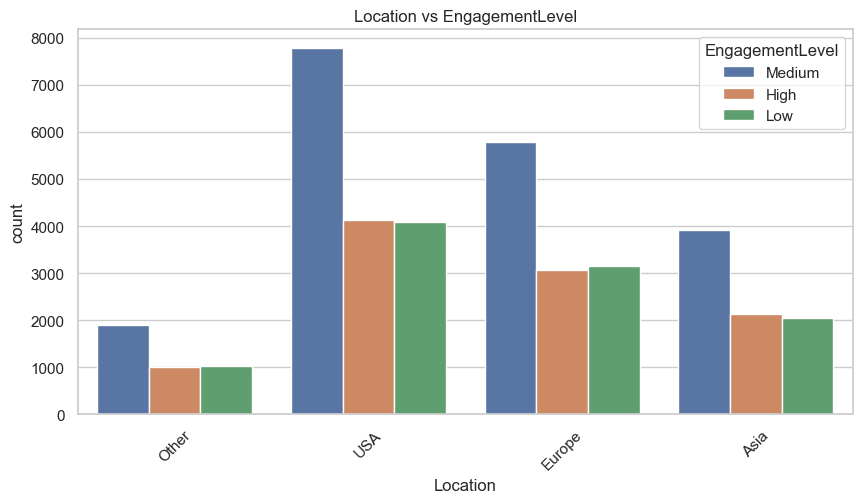

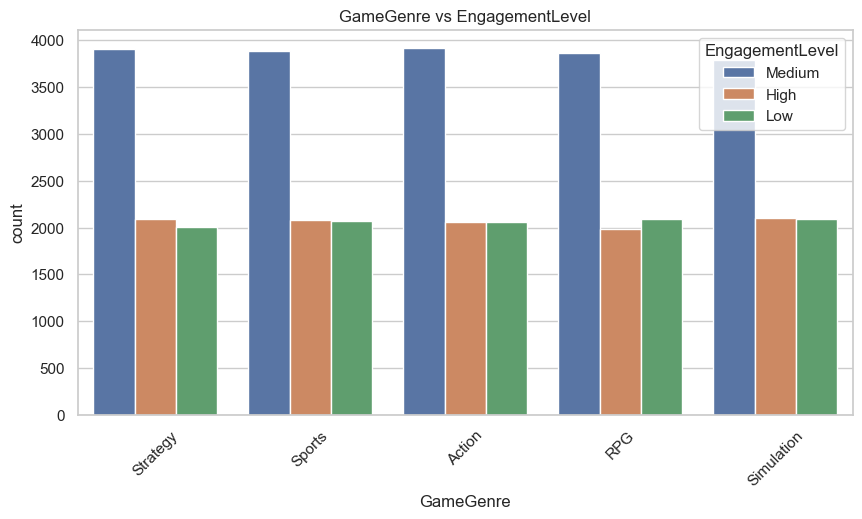

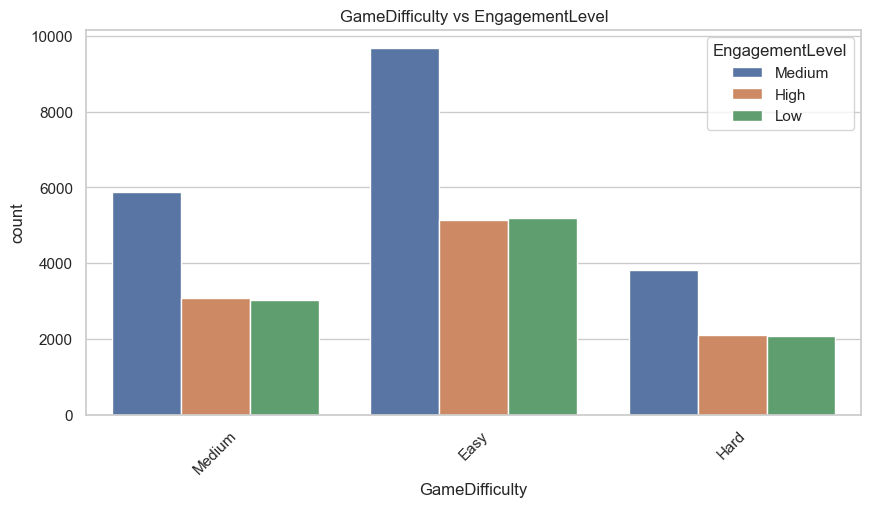

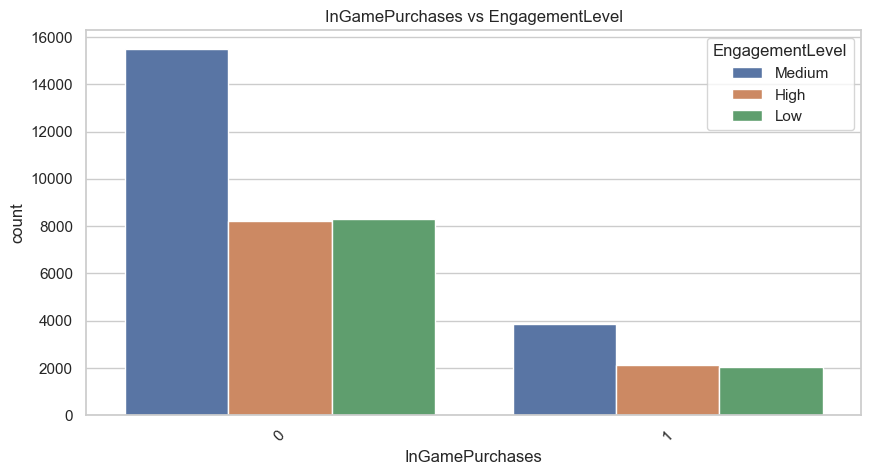

In [12]:
cat_cols_no_target = ['Gender', 'Location', 'GameGenre', 'GameDifficulty', 'InGamePurchases']

for col in cat_cols_no_target:
    plt.figure()
    sns.countplot(data=df, x=col, hue='EngagementLevel')
    plt.title(f'{col} vs EngagementLevel')
    plt.xticks(rotation=45)
    plt.legend(title='EngagementLevel')
    plt.show()

### 6.4 Multivariate Analysis

We'll check numeric feature relationships using a **correlation heatmap**.


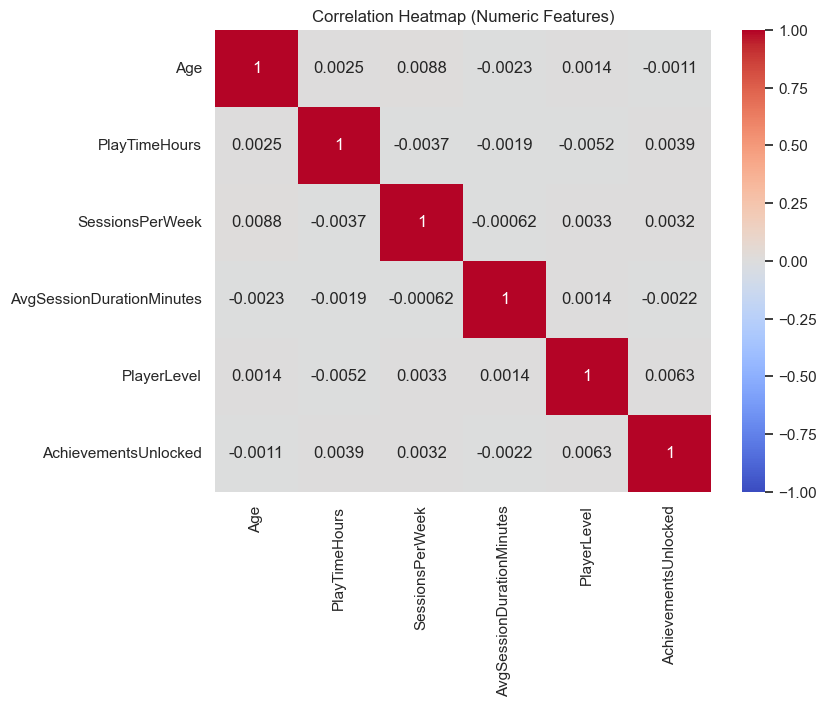

In [13]:
corr = df[numeric_cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True,vmax=1,vmin=-1,cmap="coolwarm")
plt.title('Correlation Heatmap (Numeric Features)')
plt.show()

### Observation (EDA)

While interpreting EDA, focus on:
- Which features show clear separation across engagement classes (good predictive potential)
- Whether any numeric variables are highly correlated (may not matter much for trees, but still useful insight)
- Whether some categorical groups strongly map to engagement

Next, we will prepare data for modeling.


## 7) Feature Engineering & Preprocessing

**Decisions:**
1. Drop `PlayerID` (identifier, not a behavioral feature)
2. Separate features (X) and target (y)
3. Split into train/test sets (stratified to preserve class ratios)
4. One-hot encode categorical features

In [14]:
# Drop identifier

df_model = df.drop(columns=['PlayerID'])

X = df_model.drop(columns=['EngagementLevel'])
y = df_model['EngagementLevel']

print('X shape:', X.shape)
print('y distribution:\n', y.value_counts())


X shape: (40034, 11)
y distribution:
 EngagementLevel
Medium    19374
High      10336
Low       10324
Name: count, dtype: int64


In [20]:
# Train-test split (stratified)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('Train:', X_train.shape, '| Test:', X_test.shape)
print("Y_train:",y_train.shape,'Y_test:',y_test.shape)

Train: (32027, 11) | Test: (8007, 11)
Y_train: (32027,) Y_test: (8007,)


In [16]:
categorical_features = ['Gender', 'Location', 'GameGenre', 'GameDifficulty']
numeric_features = [
    'Age', 'PlayTimeHours', 'InGamePurchases', 'SessionsPerWeek',
    'AvgSessionDurationMinutes', 'PlayerLevel', 'AchievementsUnlocked'
]

preprocess = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('num', 'passthrough', numeric_features)
    ]
)

pipe_base = Pipeline(steps=[
    ('preprocess', preprocess),
    ('model', DecisionTreeClassifier(random_state=42))
])
pipe_base

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Gender', 'Location',
                                                   'GameGenre',
                                                   'GameDifficulty']),
                                                 ('num', 'passthrough',
                                                  ['Age', 'PlayTimeHours',
                                                   'InGamePurchases',
                                                   'SessionsPerWeek',
                                                   'AvgSessionDurationMinutes',
                                                   'PlayerLevel',
                                                   'AchievementsUnlocked'])])),
                ('model', DecisionTreeClassifier(random_state=42))])

In [23]:
x_train_enc = preprocess.fit_transform(X_train)
feature_names = preprocess.get_feature_names_out()
x_train_enc = pd.DataFrame(x_train_enc.toarray() if hasattr(x_train_enc, 'toarray') else x_train_enc,
                           columns=feature_names)
print(x_train_enc.shape)
print(list(feature_names))

(32027, 21)
['cat__Gender_Female', 'cat__Gender_Male', 'cat__Location_Asia', 'cat__Location_Europe', 'cat__Location_Other', 'cat__Location_USA', 'cat__GameGenre_Action', 'cat__GameGenre_RPG', 'cat__GameGenre_Simulation', 'cat__GameGenre_Sports', 'cat__GameGenre_Strategy', 'cat__GameDifficulty_Easy', 'cat__GameDifficulty_Hard', 'cat__GameDifficulty_Medium', 'num__Age', 'num__PlayTimeHours', 'num__InGamePurchases', 'num__SessionsPerWeek', 'num__AvgSessionDurationMinutes', 'num__PlayerLevel', 'num__AchievementsUnlocked']


## 8) Baseline Model: Decision Tree Classifier

We start with a **basic decision tree**.

Why Decision Tree?
- Easy to interpret (rules)
- Works with non-linear relationships
- Handles mixed-type data once categories are encoded

We'll evaluate using:
- Confusion matrix
- Accuracy
- Classification report (precision / recall / f1-score)


In [24]:
pipe_base.fit(X_train, y_train)
y_pred_base = pipe_base.predict(X_test)
print('Accuracy (baseline)', accuracy_score(y_test, y_pred_base))

Accuracy (baseline) 0.8353940302235544


In [25]:
dt_base = pipe_base.named_steps['model']
print("actual depth", dt_base.get_depth())

actual depth 33


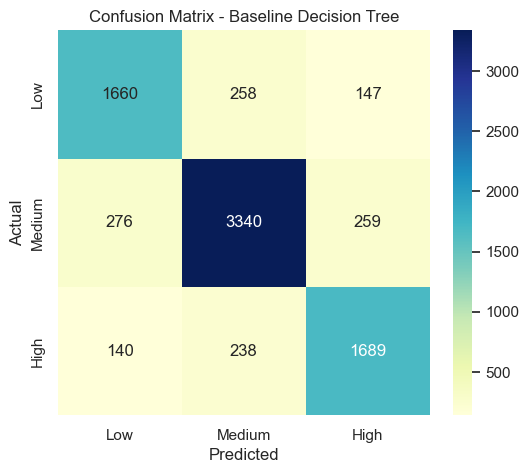

In [26]:
# Confusion matrix (Baseline)

cm = confusion_matrix(y_test, y_pred_base, labels=['Low', 'Medium', 'High'])

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=['Low','Medium','High'],cmap='YlGnBu', yticklabels=['Low','Medium','High'])
plt.title('Confusion Matrix - Baseline Decision Tree')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


In [27]:
cm

array([[1660,  258,  147],
       [ 276, 3340,  259],
       [ 140,  238, 1689]])

In [28]:
# Classification report (Baseline)

print(classification_report(y_test, y_pred_base))

              precision    recall  f1-score   support

        High       0.81      0.82      0.81      2067
         Low       0.80      0.80      0.80      2065
      Medium       0.87      0.86      0.87      3875

    accuracy                           0.84      8007
   macro avg       0.83      0.83      0.83      8007
weighted avg       0.84      0.84      0.84      8007



### Observation

- If the model struggles with a class (e.g., `Low`), check **recall** for that class.
- If precision is low for a class, the model is predicting that class too often incorrectly.

Next, we’ll interpret the model using feature importance and tree visualization.


## 9) Feature Importance (Baseline Tree)

Decision trees can provide **feature_importances_**.

Interpretation:
- Higher importance means the feature contributed more to reducing impurity across splits.
- Importance is not perfect (can be biased toward high-cardinality features), but it’s a useful starting point.


In [29]:
names = pipe_base.named_steps['preprocess'].get_feature_names_out()
importances = pd.Series(dt_base.feature_importances_, index=names)
importances_sorted = importances.sort_values(ascending=False)
importances_sorted.head(15)

num__SessionsPerWeek              0.451114
num__AvgSessionDurationMinutes    0.305809
num__PlayerLevel                  0.062500
num__AchievementsUnlocked         0.059103
num__PlayTimeHours                0.042518
num__Age                          0.025199
cat__Location_Europe              0.004449
cat__GameDifficulty_Hard          0.004335
cat__Location_Asia                0.004293
cat__GameGenre_Simulation         0.003988
cat__Location_USA                 0.003815
cat__GameDifficulty_Easy          0.003627
cat__GameDifficulty_Medium        0.003556
cat__GameGenre_RPG                0.003551
cat__GameGenre_Sports             0.003525
dtype: float64

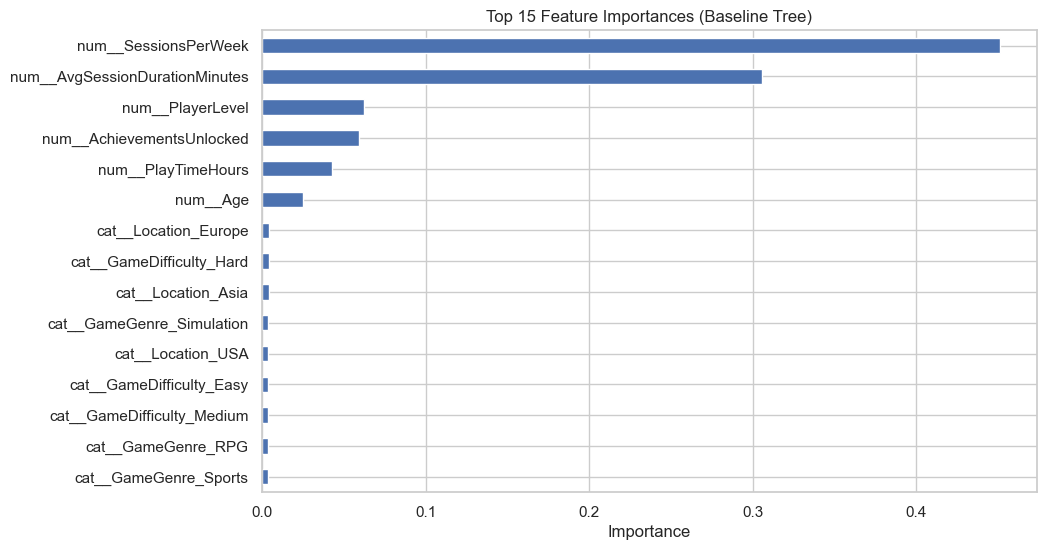

In [30]:
# Plot top 15 important features

plt.figure(figsize=(10, 6))
importances_sorted.head(15).sort_values().plot(kind='barh')
plt.title('Top 15 Feature Importances (Baseline Tree)')
plt.xlabel('Importance')
plt.show()


## 10) Visualize the Decision Tree (Baseline)

A full tree can become very large. For readability, we plot only the **top few levels** using `max_depth` in the plot.


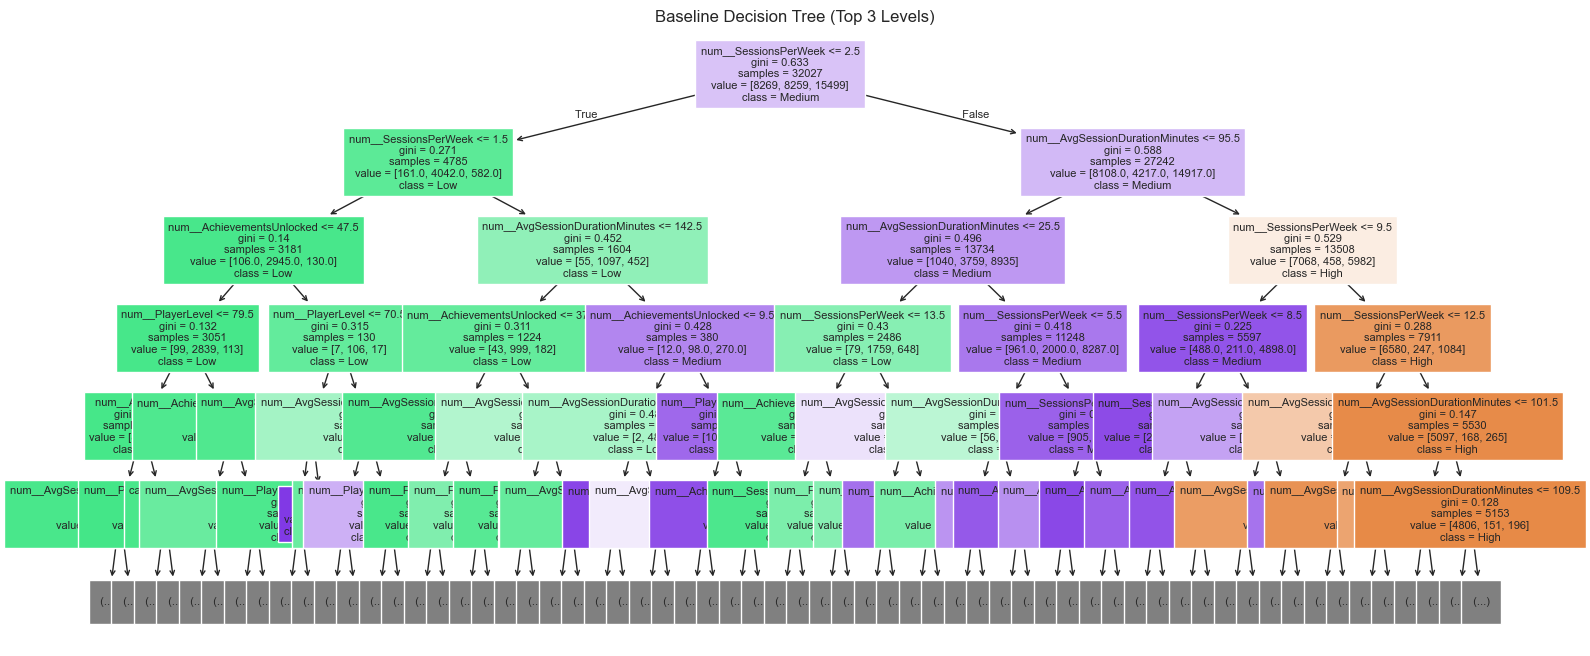

In [32]:
plt.figure(figsize=(18, 8))
plot_tree(
    dt_base,
    feature_names=x_train_enc.columns.tolist(),  
    class_names=dt_base.classes_.tolist(), # Good practice to convert this too
    filled=True,
    max_depth=5,
    fontsize=8
)
plt.title('Baseline Decision Tree (Top 3 Levels)')
plt.show()


In [33]:
# !pip install graphviz

In [35]:
from sklearn.tree import export_graphviz

dot_data = export_graphviz(
    dt_base,
    out_file=None,
    feature_names=x_train_enc.columns.tolist(),
    class_names=dt_base.classes_.tolist(),
    filled=True,
    rounded=True,
    special_characters=True,
    max_depth=5
)

print(dot_data)

digraph Tree {
node [shape=box, style="filled, rounded", color="black", fontname="helvetica"] ;
edge [fontname="helvetica"] ;
0 [label=<num__SessionsPerWeek &le; 2.5<br/>gini = 0.633<br/>samples = 32027<br/>value = [8269, 8259, 15499]<br/>class = Medium>, fillcolor="#d9c3f7"] ;
1 [label=<num__SessionsPerWeek &le; 1.5<br/>gini = 0.271<br/>samples = 4785<br/>value = [161.0, 4042.0, 582.0]<br/>class = Low>, fillcolor="#5cea97"] ;
0 -> 1 [labeldistance=2.5, labelangle=45, headlabel="True"] ;
2 [label=<num__AchievementsUnlocked &le; 47.5<br/>gini = 0.14<br/>samples = 3181<br/>value = [106.0, 2945.0, 130.0]<br/>class = Low>, fillcolor="#48e78b"] ;
1 -> 2 ;
3 [label=<num__PlayerLevel &le; 79.5<br/>gini = 0.132<br/>samples = 3051<br/>value = [99, 2839, 113]<br/>class = Low>, fillcolor="#47e78a"] ;
2 -> 3 ;
4 [label=<num__Age &le; 25.5<br/>gini = 0.118<br/>samples = 2483<br/>value = [82, 2330, 71]<br/>class = Low>, fillcolor="#46e789"] ;
3 -> 4 ;
5 [label=<num__AvgSessionDurationMinutes &le; 12

## 11) Hyperparameter Tuning (Decision Tree)

Key hyperparameters:
- **max_depth**: controls depth (prevents overfitting)
- **min_samples_split**: min samples required to split a node
- **min_samples_leaf**: min samples at a leaf
- **criterion**: impurity measure (`gini` or `entropy`)

We'll use **GridSearchCV** to find better settings.


In [53]:
param_grid = {
    'model__criterion': ['gini', 'entropy'],
    'model__max_depth': [3, 5, 8, 12, None],
    'model__min_samples_split': [2, 5, 10, 20],
    'model__min_samples_leaf': [1, 2, 5, 10]
}

grid = GridSearchCV(
    estimator=pipe_base,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid.fit(X_train, y_train)

print('Best Params:', grid.best_params_)
print('Best CV Accuracy:', grid.best_score_)

Best Params: {'model__criterion': 'entropy', 'model__max_depth': 12, 'model__min_samples_leaf': 10, 'model__min_samples_split': 2}
Best CV Accuracy: 0.905517290459788


In [55]:
pipe_tuned = grid.best_estimator_
dt_tuned = pipe_tuned.named_steps['model']

y_pred_tuned = pipe_tuned.predict(X_test)

### Observation

- Tuning often improves generalization by limiting depth or enforcing minimum samples.
- Still, decision trees can overfit. A strong next step is **pruning**.


## 12) Tree Pruning (Cost-Complexity Pruning)

Even after tuning, trees can be complex. **Cost-complexity pruning** finds a good balance between:
- Model accuracy
- Model simplicity (smaller tree)

We will:
1. Get candidate `ccp_alpha` values
2. Train multiple pruned trees
3. Pick the best alpha based on validation accuracy
4. Retrain final pruned model and evaluate on test


In [57]:
# Create a validation split from training data for pruning selection

X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    x_train_enc, y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print('Train_sub:', X_train_sub.shape, '| Val:', X_val.shape)


Train_sub: (25621, 21) | Val: (6406, 21)


In [58]:
# Get pruning path from the tuned model structure
np.set_printoptions(suppress=True, precision=6)
path = dt_tuned.cost_complexity_pruning_path(X_train_sub, y_train_sub)
ccp_alphas = path.ccp_alphas

print('Number of candidate alphas:', len(ccp_alphas))
print('First 10 alphas:', ccp_alphas[:10])


Number of candidate alphas: 652
First 10 alphas: [0.       0.       0.000006 0.000011 0.000018 0.000018 0.000025 0.000027
 0.000028 0.000031]


In [59]:
# Train trees for a subset of alphas (to keep it fast and readable)

alphas_to_try = np.unique(np.round(ccp_alphas, 6))

val_scores = []
models = []

for alpha in alphas_to_try:
    model = DecisionTreeClassifier(
        random_state=42,
        ccp_alpha=alpha,
        criterion=dt_tuned.criterion,
        max_depth=dt_tuned.max_depth,
        min_samples_split=dt_tuned.min_samples_split,
        min_samples_leaf=dt_tuned.min_samples_leaf
    )
    model.fit(X_train_sub, y_train_sub)
    pred_val = model.predict(X_val)
    acc_val = accuracy_score(y_val, pred_val)

    val_scores.append(acc_val)
    models.append(model)

best_idx = int(np.argmax(val_scores))
best_alpha = alphas_to_try[best_idx]

print('Best ccp_alpha:', best_alpha)
print('Best validation accuracy:', val_scores[best_idx])
print(val_scores)
print(models)

Best ccp_alpha: 0.000358
Best validation accuracy: 0.9032157352482048
[0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8985326256634405, 0.8996253512332189, 0.8996253512332189, 0.8996253512332189, 0.8996253

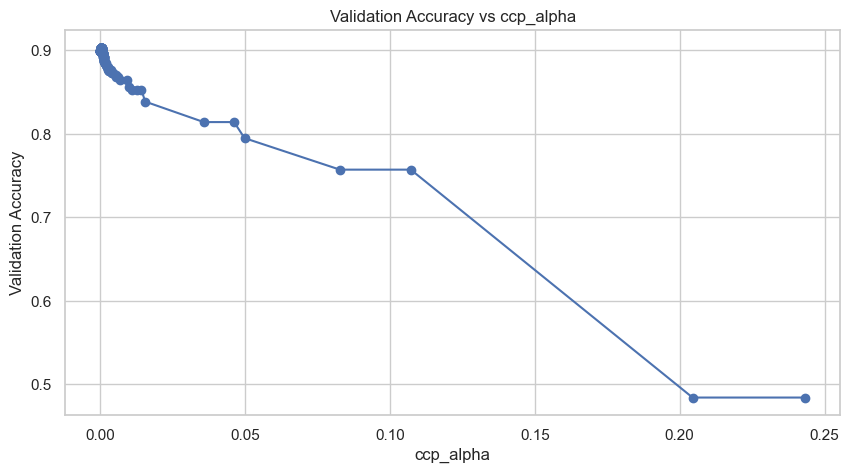

In [60]:
# Plot validation accuracy vs ccp_alpha

plt.figure(figsize=(10, 5))
plt.plot(alphas_to_try, val_scores, marker='o')
plt.title('Validation Accuracy vs ccp_alpha')
plt.xlabel('ccp_alpha')
plt.ylabel('Validation Accuracy')
plt.show()


In [66]:
# Train final pruned pipeline on full training data (train set)

pipe_pruned = Pipeline(steps=[
    ('preprocess', preprocess),
    ('model', DecisionTreeClassifier(
        random_state=42,
        ccp_alpha=best_alpha,
        criterion=dt_tuned.criterion,
        max_depth=dt_tuned.max_depth,
        min_samples_split=dt_tuned.min_samples_split,
        min_samples_leaf=dt_tuned.min_samples_leaf
    ))
])

pipe_pruned.fit(X_train, y_train)

y_pred_pruned = pipe_pruned.predict(X_test)

print('Accuracy (Pruned):', accuracy_score(y_test, y_pred_pruned))
print('\nClassification Report (Pruned):\n')
print(classification_report(y_test, y_pred_pruned))

Accuracy (Pruned): 0.9023354564755839

Classification Report (Pruned):

              precision    recall  f1-score   support

        High       0.91      0.88      0.90      2067
         Low       0.89      0.87      0.88      2065
      Medium       0.90      0.93      0.92      3875

    accuracy                           0.90      8007
   macro avg       0.90      0.89      0.90      8007
weighted avg       0.90      0.90      0.90      8007



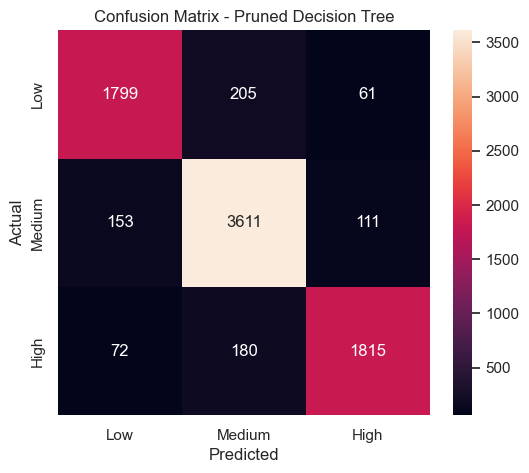

In [67]:
# Confusion matrix (Pruned)

cm_pruned = confusion_matrix(y_test, y_pred_pruned, labels=['Low', 'Medium', 'High'])

plt.figure(figsize=(6, 5))
sns.heatmap(cm_pruned, annot=True, fmt='d', xticklabels=['Low','Medium','High'], yticklabels=['Low','Medium','High'])
plt.title('Confusion Matrix - Pruned Decision Tree')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


## 13) Visualize: Baseline Tree vs Pruned Tree

We compare the top levels of each tree.


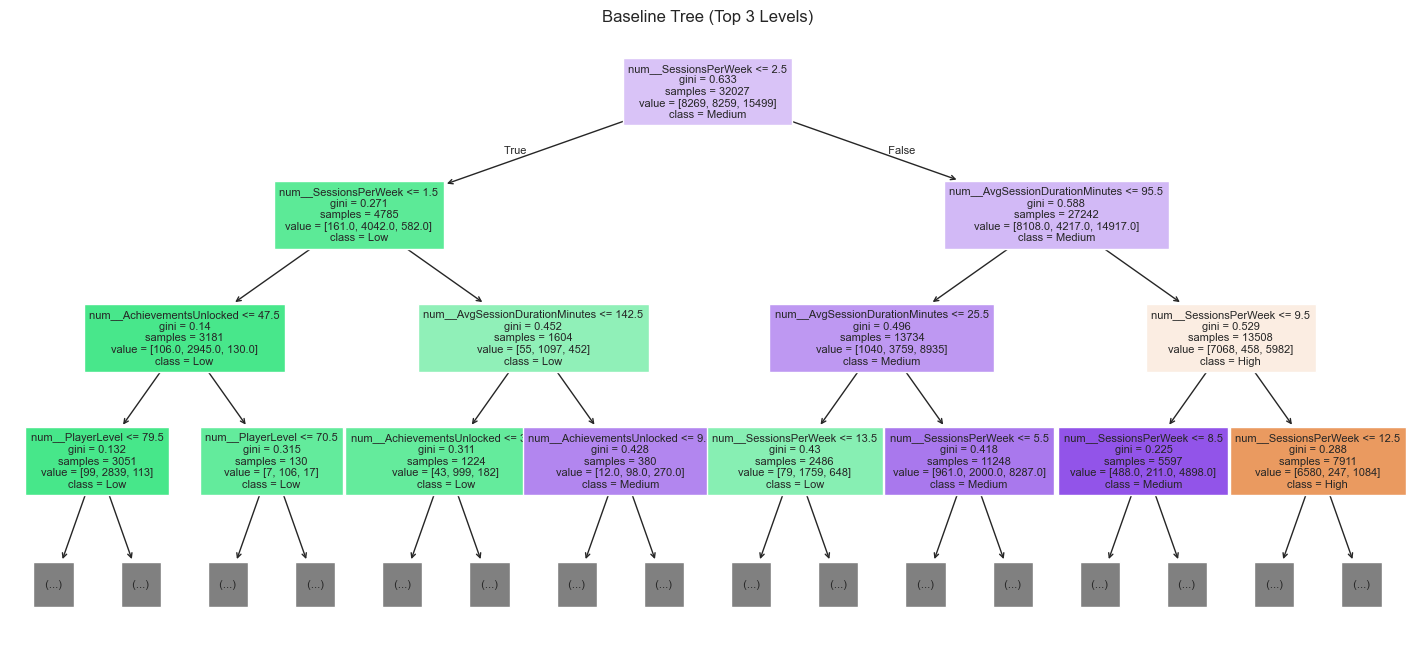

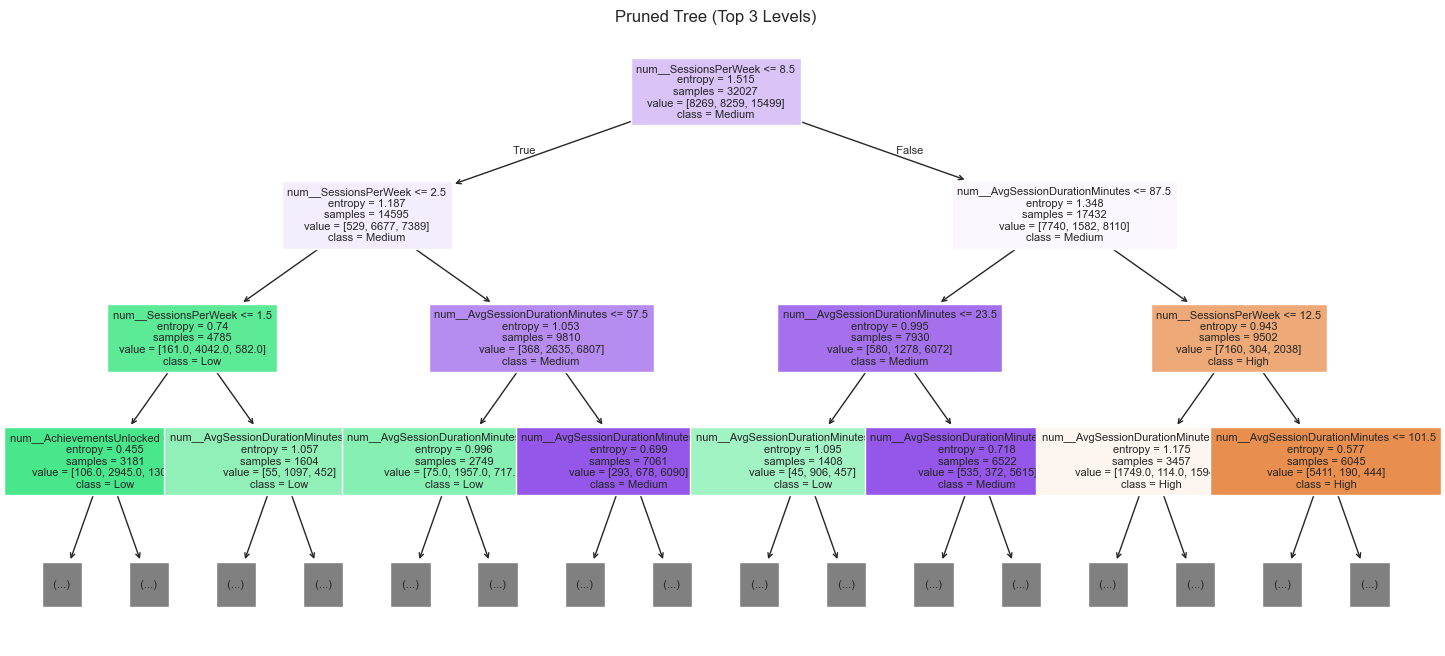

In [69]:
# --- Baseline Tree Visualization ---
plt.figure(figsize=(18, 8))
plot_tree(
    dt_base,
    # FIX: Added .tolist() to convert Index to list
    feature_names=x_train_enc.columns.tolist(),
    # FIX: Added .tolist() to convert Array to list
    class_names=dt_base.classes_.tolist(),
    filled=True,
    max_depth=3,
    fontsize=8
)
plt.title('Baseline Tree (Top 3 Levels)')
plt.show()

# --- Pruned Tree Visualization ---
plt.figure(figsize=(18, 8))
plot_tree(
    dt_pruned,
    # FIX: Added .tolist() here as well
    feature_names=x_train_enc.columns.tolist(),
    # FIX: Added .tolist() here as well
    class_names=dt_pruned.classes_.tolist(),
    filled=True,
    max_depth=3,
    fontsize=8
)
plt.title('Pruned Tree (Top 3 Levels)')
plt.show()

## 14) Model Comparison & Final Model Selection

We'll compare:
- Baseline tree
- Tuned tree (GridSearchCV)
- Pruned tree

We'll use:
- **Accuracy**
- **Macro F1-score** (treats all classes equally)


In [70]:
from sklearn.metrics import f1_score

results = []

# Baseline
results.append({
    'Model': 'Baseline Tree',
    'Accuracy': accuracy_score(y_test, y_pred_base),
    'Macro F1': f1_score(y_test, y_pred_base, average='macro')
})

# Tuned
results.append({
    'Model': 'Tuned Tree (GridSearch)',
    'Accuracy': accuracy_score(y_test, y_pred_tuned),
    'Macro F1': f1_score(y_test, y_pred_tuned, average='macro')
})

# Pruned
results.append({
    'Model': 'Pruned Tree (ccp_alpha)',
    'Accuracy': accuracy_score(y_test, y_pred_pruned),
    'Macro F1': f1_score(y_test, y_pred_pruned, average='macro')
})

pd.DataFrame(results).sort_values(by=['Macro F1', 'Accuracy'], ascending=False)


,Model,Accuracy,Macro F1
1,Tuned Tree (GridSearch),0.902335,0.897715
2,Pruned Tree (ccp_alpha),0.902335,0.897626
0,Baseline Tree,0.835394,0.826554


### Final Model Choice (Recommended)

In most real projects, we choose the model that gives:
- Strong performance on unseen test data
- Balanced performance across classes (macro-F1)
- Simpler structure (easier to explain and deploy)

**Typical outcome:** the **Pruned Tree** often performs similarly (or better) than the tuned model while being simpler and less overfit.




In [102]:
# Fit pipeline on raw (non-encoded) data

pipeline_model.fit(X_train, y_train)

y_pred_pipe = pipeline_model.predict(X_test)

print('Accuracy (Pipeline):', accuracy_score(y_test, y_pred_pipe))
print('\nClassification Report (Pipeline):\n')
print(classification_report(y_test, y_pred_pipe))


Accuracy (Pipeline): 0.9023354564755839

Classification Report (Pipeline):

              precision    recall  f1-score   support

        High       0.91      0.88      0.90      2067
         Low       0.89      0.87      0.88      2065
      Medium       0.90      0.93      0.92      3875

    accuracy                           0.90      8007
   macro avg       0.90      0.89      0.90      8007
weighted avg       0.90      0.90      0.90      8007



In [71]:
import os
os.getcwd()

'C:\\Users\\nazmi'

In [104]:
# # Save the pipeline (model + preprocessing) for later use

# MODEL_PATH = 'final_engagement_tree_pipeline.joblib'
# joblib.dump(pipeline_model, MODEL_PATH)
# print('Saved pipeline to:', MODEL_PATH)


Saved pipeline to: final_engagement_tree_pipeline.joblib


In [107]:
# # Example: Load and predict on a single new player record

# loaded_model = joblib.load(MODEL_PATH)

# sample_player = pd.DataFrame([{
#     'Age': 26,
#     'Gender': 'Male',
#     'Location': 'USA',
#     'GameGenre': 'Action',
#     'PlayTimeHours': 7.5,
#     'InGamePurchases': 1,
#     'GameDifficulty': 'Medium',
#     'SessionsPerWeek': 3,
#     'AvgSessionDurationMinutes': 135,
#     'PlayerLevel': 22,
#     'AchievementsUnlocked': 15
# }])

# loaded_model.predict(sample_player)


array(['Medium'], dtype=object)

## 16) Conclusion & Next Steps

### What we accomplished
- Built a full ML workflow for predicting player engagement
- Trained a baseline Decision Tree
- Improved it with tuning and pruning
- Visualized and interpreted the tree
- Built a production-style sklearn Pipeline and saved it

### Next steps (optional improvements)
- Try **RandomForest / GradientBoosting / XGBoost** for higher accuracy
- Handle possible class imbalance using class weights or resampling
- Use **SHAP** for more reliable feature impact explanations
- Monitor model performance over time (players and games evolve!)


In [72]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import f1_score, recall_score
from xgboost import XGBClassifier

# XGBoost requires labels(0,1,2),not text
le = LabelEncoder().fit(['Low', 'Medium', 'High'])
y_train_num = le.transform(y_train)

results = []

def run_model(name, model, use_numbers=False, sample_weight=None):
    pipe = Pipeline(steps=[('preprocess', preprocess), ('model', model)])
    fit_params = {} if sample_weight is None else {'model__sample_weight': sample_weight}

    if use_numbers:                       # sirf XGBoost ke liye
        pipe.fit(X_train, y_train_num, **fit_params)
        pred = le.inverse_transform(pipe.predict(X_test))
    else:
        pipe.fit(X_train, y_train, **fit_params)
        pred = pipe.predict(X_test)

    rec = recall_score(y_test, pred, average=None, labels=['Low', 'Medium', 'High'])
    results.append({
        'Model': name,
        'Accuracy': round(accuracy_score(y_test, pred), 4),
        'Macro F1': round(f1_score(y_test, pred, average='macro'), 4),
        'Recall Low': round(rec[0], 3),
        'Recall Medium': round(rec[1], 3),
        'Recall High': round(rec[2], 3),
    })
    return pipe

rf  = run_model('Random Forest', RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1))
gb  = run_model('Gradient Boosting', GradientBoostingClassifier(random_state=42))
xgb = run_model('XGBoost', XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=6,
                                         random_state=42, eval_metric='mlogloss'), use_numbers=True)

pd.DataFrame(results)

,Model,Accuracy,Macro F1,Recall Low,Recall Medium,Recall High
0,Random Forest,0.8936,0.8882,0.858,0.942,0.839
1,Gradient Boosting,0.9037,0.8986,0.862,0.942,0.873
2,XGBoost,0.9132,0.9082,0.886,0.947,0.878


**Inference (three ensemble models)**
- XGBoost is the best of the three: accuracy **0.9132** and macro F1 **0.9082**, ahead of Gradient Boosting (0.9037) and Random Forest (0.8936).
- All three models find **Medium** players best (recall 0.94 to 0.95) and are weakest on **High** (0.84 to 0.88) and **Low** (0.86 to 0.89).
- Every ensemble is already close to or better than the tuned decision tree (0.902), so combining many trees helps on this data.

> **In simple words:** a team of many small trees guesses better than one big tree, and XGBoost is the strongest team.

In [90]:
from sklearn.utils.class_weight import compute_sample_weight

print(y_train.value_counts(normalize=True).round(3))

sw = compute_sample_weight('balanced', y_train)   #small class gets more weights

rf_bal  = run_model('RF + class_weight', RandomForestClassifier(
              n_estimators=300, random_state=42, n_jobs=-1, class_weight='balanced'))
gb_bal  = run_model('GB + sample_weight', GradientBoostingClassifier(random_state=42),
                    sample_weight=sw)
xgb_bal = run_model('XGB + sample_weight', XGBClassifier(
              n_estimators=300, learning_rate=0.1, max_depth=6,
              random_state=42, eval_metric='mlogloss'),
              use_numbers=True, sample_weight=sw)

pd.DataFrame(results)

EngagementLevel
Medium    0.484
High      0.258
Low       0.258
Name: proportion, dtype: float64


,Model,Accuracy,Macro F1,Recall Low,Recall Medium,Recall High
0,Random Forest,0.8936,0.8882,0.858,0.942,0.839
1,Gradient Boosting,0.9037,0.8986,0.862,0.942,0.873
2,XGBoost,0.9132,0.9082,0.886,0.947,0.878
3,RF + class_weight,0.9001,0.8950,0.865,0.941,0.858
4,GB + sample_weight,0.8956,0.8921,0.905,0.893,0.891
5,XGB + sample_weight,0.9097,0.9052,0.900,0.929,0.883
6,RF + class_weight,0.9001,0.8950,0.865,0.941,0.858
7,GB + sample_weight,0.8956,0.8921,0.905,0.893,0.891
8,XGB + sample_weight,0.9097,0.9052,0.900,0.929,0.883
9,RF + class_weight,0.9001,0.8950,0.865,0.941,0.858


**Inference (class weights)**
- The classes are only mildly imbalanced (Medium 48%, High 26%, Low 26%), so weights change little.
- Weights move recall around instead of raising overall quality: for Gradient Boosting, **Low recall rises from 0.862 to 0.905** but **Medium recall falls from 0.942 to 0.893**, and accuracy drops a little (0.9037 to 0.8956).
- XGBoost keeps most of its accuracy with weights (0.9132 to 0.9097), so it handles this imbalance well.

> **In simple words:** weights make the model pay more attention to the smaller groups, but it then pays less attention to the big group. The total score does not really improve.

In [75]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import randint, uniform

xgb_pipe = Pipeline(steps=[
    ('preprocess', preprocess),
    ('model', XGBClassifier(random_state=42, eval_metric='mlogloss'))
])

param_dist = {
    'model__n_estimators':     randint(200, 700),
    'model__max_depth':        randint(3, 9),
    'model__learning_rate':    uniform(0.02, 0.18),
    'model__subsample':        uniform(0.6, 0.4),
    'model__colsample_bytree': uniform(0.6, 0.4),
    'model__min_child_weight': randint(1, 10),
    'model__gamma':            uniform(0, 0.5),
}

search = RandomizedSearchCV(
    xgb_pipe, param_dist,
    n_iter=20,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    scoring='f1_macro',
    random_state=42,
    n_jobs=-1,
)
search.fit(X_train, y_train_num)

print('Best Params:', search.best_params_)
print('Best CV Macro F1:', round(search.best_score_, 4))

xgb_tuned = search.best_estimator_
pred_tuned = le.inverse_transform(xgb_tuned.predict(X_test))

print('Test Accuracy:', round(accuracy_score(y_test, pred_tuned), 4))
print('Test Macro F1:', round(f1_score(y_test, pred_tuned, average='macro'), 4))
print(classification_report(y_test, pred_tuned))

Best Params: {'model__colsample_bytree': np.float64(0.8493192507310232), 'model__gamma': np.float64(0.1654490124263246), 'model__learning_rate': np.float64(0.031440503051484256), 'model__max_depth': 8, 'model__min_child_weight': 8, 'model__n_estimators': 492, 'model__subsample': np.float64(0.8918424713352255)}
Best CV Macro F1: 0.9111
Test Accuracy: 0.9159
Test Macro F1: 0.911
              precision    recall  f1-score   support

        High       0.92      0.88      0.90      2067
         Low       0.92      0.89      0.90      2065
      Medium       0.91      0.95      0.93      3875

    accuracy                           0.92      8007
   macro avg       0.92      0.91      0.91      8007
weighted avg       0.92      0.92      0.92      8007



**Inference (errors of the final model)**
- Out of 8,007 test players, about **7,300 are predicted correctly** (accuracy about 91.6%).
- Almost all mistakes are between **neighbouring classes**: High wrongly called Medium (about 180 players) and Low wrongly called Medium (about 160). A High player called Low, or the reverse, is rare (60 to 70 each).
- Medium has the best recall (0.95); High (0.88) and Low (0.89) are slightly lower. Medium is the "middle" class, so the model sometimes pulls borderline players towards it.

> **In simple words:** when the model is wrong, it is usually off by only one level, such as calling a very active player "medium" instead of "high".

**Inference (tuned XGBoost)**
- Best settings: `max_depth` 8, `learning_rate` 0.031, `n_estimators` 492, `subsample` 0.89, `colsample_bytree` 0.85, `min_child_weight` 8.
- Cross-validated macro F1 is **0.9111** and test macro F1 is **0.9110**. They are almost equal, so the model is **not overfitting** and the score is stable.
- Test accuracy is **0.9159**, only +0.3% above untuned XGBoost (0.9132). This data seems to have a ceiling around 91 to 92%.
- Precision and recall are 0.88 to 0.95 for all three classes, so no class is left behind.

- fine-tuning gave a small gain, and the same score on practice tests and the final test shows the model is honest.

In [76]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, RandomOverSampler
from sklearn.utils.class_weight import compute_sample_weight


best = {k.replace('model__', ''): v for k, v in search.best_params_.items()}

def make_xgb():
    return XGBClassifier(random_state=42, eval_metric='mlogloss', **best)

rows = []

def evaluate(name, pipe, fit_params=None):
    pipe.fit(X_train, y_train_num, **(fit_params or {}))
    pred = le.inverse_transform(pipe.predict(X_test))
    rec = recall_score(y_test, pred, average=None, labels=['Low', 'Medium', 'High'])
    rows.append({
        'Model': name,
        'Accuracy': round(accuracy_score(y_test, pred), 4),
        'Macro F1': round(f1_score(y_test, pred, average='macro'), 4),
        'Recall Low': round(rec[0], 3),
        'Recall Medium': round(rec[1], 3),
        'Recall High': round(rec[2], 3),
    })


evaluate('XGB tuned', Pipeline([('preprocess', preprocess), ('model', make_xgb())]))


sw = compute_sample_weight('balanced', y_train)
evaluate('XGB tuned + weights',
         Pipeline([('preprocess', preprocess), ('model', make_xgb())]),
         {'model__sample_weight': sw})


evaluate('XGB tuned + RandomOverSampler',
         ImbPipeline([('preprocess', preprocess),
                      ('over', RandomOverSampler(random_state=42)),
                      ('model', make_xgb())]))


evaluate('XGB tuned + SMOTE',
         ImbPipeline([('preprocess', preprocess),
                      ('smote', SMOTE(random_state=42)),
                      ('model', make_xgb())]))

pd.DataFrame(rows)

  File "C:\Users\nazmi\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\nazmi\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\nazmi\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\nazmi\anaconda3\Lib\subprocess.

,Model,Accuracy,Macro F1,Recall Low,Recall Medium,Recall High
0,XGB tuned,0.9159,0.9110,0.892,0.949,0.878
1,XGB tuned + weights,0.9141,0.9096,0.906,0.933,0.887
2,XGB tuned + RandomOverSampler,0.9144,0.9099,0.904,0.935,0.886
3,XGB tuned + SMOTE,0.9133,0.9085,0.888,0.946,0.878


**Inference (imbalance handling)**
- All four options are very close: macro F1 between **0.9085 and 0.9110**. Doing nothing is slightly the best (0.9110).
- Weights and random oversampling raise **Low recall** a little (0.892 to about 0.905) but reduce Medium recall (0.949 to about 0.934).
- SMOTE (making synthetic players) gives no gain at all, so the extra complexity is not worth it.
- Decision: keep **tuned XGBoost without resampling**. Use the weighted version only if catching Low-engagement players matters more than overall accuracy.

> **In simple words:** the data is balanced enough, so special tricks do not help. We keep the simple version.

**Inference (all models compared)**
- Ranking by macro F1: **XGBoost (tuned) 0.911**, XGBoost 0.908, Gradient Boosting 0.899, pruned/tuned Decision Tree about 0.898, Random Forest 0.888, baseline Decision Tree 0.827.
- The baseline tree was memorising (depth 33). Tuning and pruning lifted it from 0.835 to **0.902 accuracy**, and boosting lifted it again to **0.916**.
- Random Forest is not better than the tuned single tree here, because forest trees are grown deep and noisy on this data.

> **In simple words:** each step (tuning, pruning, boosting) made the model better, and the tuned XGBoost is the winner.

In [77]:
# import joblib

# MODEL_PATH = 'final_engagement_xgb.joblib'
# joblib.dump({'model': xgb_tuned, 'label_encoder': le}, MODEL_PATH)

# art = joblib.load(MODEL_PATH)

# sample_player = pd.DataFrame([{
#     'Age': 26, 'Gender': 'Male', 'Location': 'USA', 'GameGenre': 'Action',
#     'PlayTimeHours': 7.5, 'InGamePurchases': 1, 'GameDifficulty': 'Medium',
#     'SessionsPerWeek': 3, 'AvgSessionDurationMinutes': 135,
#     'PlayerLevel': 22, 'AchievementsUnlocked': 15
# }])

# pred_label = art['label_encoder'].inverse_transform(art['model'].predict(sample_player))
# proba = pd.DataFrame(art['model'].predict_proba(sample_player),
#                      columns=art['label_encoder'].classes_).round(2)

# print('Predicted engagement:', pred_label[0])
# proba

In [79]:
!pip install shap

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   --------------------------- ------------ 524.3/751.9 kB 1.3 MB/s eta 0:00:01
   ---------------------------------------- 751.9/751.9 kB 1.3 MB/s eta 0:00:00

   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]



In [80]:
import shap

pre_fitted = xgb_tuned.named_steps['preprocess']
xgb_model  = xgb_tuned.named_steps['model']

names = [n.split('__', 1)[1] for n in pre_fitted.get_feature_names_out()]


X_shap = X_test.sample(1000, random_state=42)
X_enc = pre_fitted.transform(X_shap)
X_enc = X_enc.toarray() if hasattr(X_enc, 'toarray') else X_enc
X_enc = pd.DataFrame(X_enc, columns=names)

explainer = shap.TreeExplainer(xgb_model)
shap_values = np.array(explainer.shap_values(X_enc))

classes = list(le.classes_)          # ['High', 'Low', 'Medium']
print(shap_values.shape, classes)

(1000, 21, 3) [np.str_('High'), np.str_('Low'), np.str_('Medium')]


In [81]:
imp = pd.DataFrame(np.abs(shap_values).mean(axis=0), index=names, columns=classes)

def original_name(n):
    for c in categorical_features:
        if n.startswith(c + '_'):
            return c
    return n

imp_orig = imp.groupby(original_name).sum()
imp_orig['All classes'] = imp_orig.sum(axis=1)
imp_orig = imp_orig.sort_values('All classes', ascending=False)

imp_orig.round(3)

,High,Low,Medium,All classes
SessionsPerWeek,1.033,0.978,0.867,2.878
AvgSessionDurationMinutes,0.925,0.646,0.652,2.223
AchievementsUnlocked,0.092,0.183,0.115,0.391
PlayerLevel,0.100,0.171,0.107,0.378
PlayTimeHours,0.083,0.072,0.056,0.211
Age,0.079,0.058,0.047,0.183
GameGenre,0.064,0.069,0.047,0.180
Location,0.045,0.048,0.037,0.130
GameDifficulty,0.047,0.033,0.031,0.112
Gender,0.018,0.016,0.010,0.044


**Inference (SHAP importance)**
- **SessionsPerWeek (2.88)** and **AvgSessionDurationMinutes (2.22)** dominate. Together they are about 80% of all impact.
- **AchievementsUnlocked (0.39)** and **PlayerLevel (0.38)** come next, and they matter more for the **Low** class (0.18) than for High or Medium (0.10 to 0.12).
- All other columns are between 0.04 and 0.21, so they hardly change any prediction.
- This agrees with permutation importance and with the decision tree, so three different methods tell the same story.

> **In simple words:** the game cares about only two things: how many times a week a player plays and how long each session is.

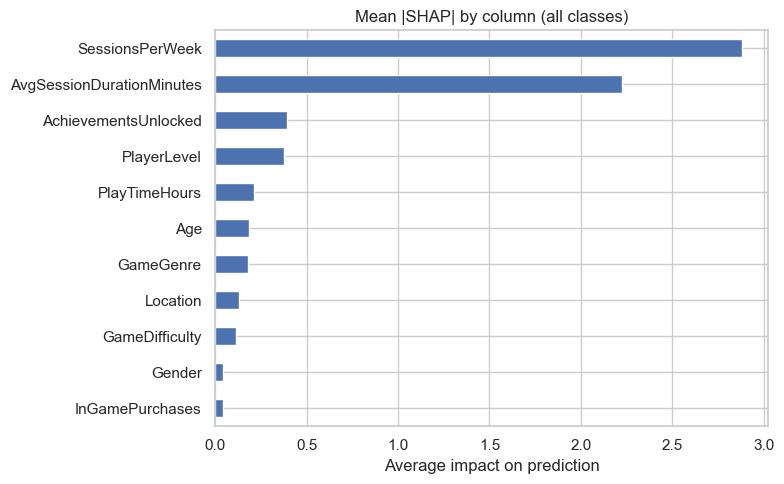

In [82]:
imp_orig['All classes'].sort_values().plot(kind='barh', figsize=(8, 5))
plt.title('Mean |SHAP| by column (all classes)')
plt.xlabel('Average impact on prediction')
plt.tight_layout()
plt.show()

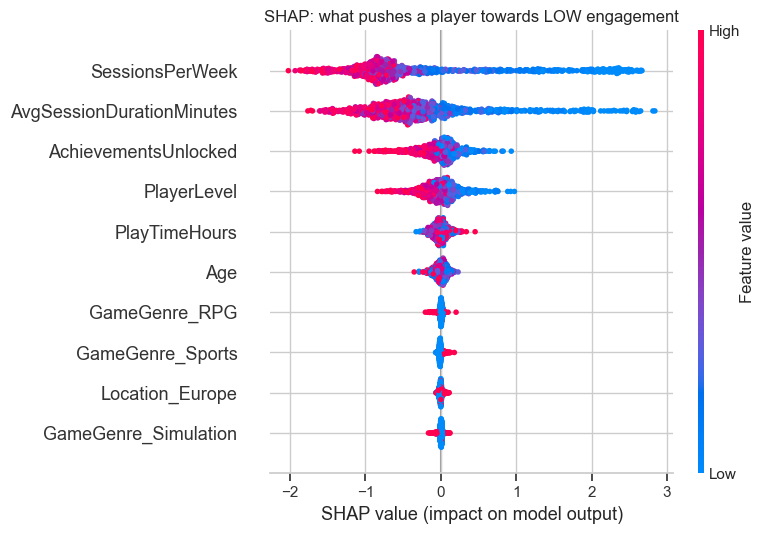

In [83]:
k = classes.index('Low')

shap.summary_plot(shap_values[:, :, k], X_enc, max_display=10, show=False)
plt.title('SHAP: what pushes a player towards LOW engagement')
plt.tight_layout()
plt.show()

**Inference (direction of impact)**
- Each dot is a player. Dots on the right push the model towards **Low** engagement.
- For `SessionsPerWeek` and `AvgSessionDurationMinutes`, **low values (blue) sit on the right** and high values (red) on the left. So few sessions and short sessions mean Low engagement, and many long sessions mean the opposite.
- This matches common sense, so the model learned a sensible rule instead of an accident in the data.

> **In simple words:** players who play rarely and for short times are the ones likely to drift away.

In [85]:
# import numpy as np
# from scipy.stats import ks_2samp

# def psi(expected, actual, bins=10):
#     cuts = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
#     cuts[0], cuts[-1] = -np.inf, np.inf
#     e = np.histogram(expected, cuts)[0] / len(expected)
#     a = np.histogram(actual, cuts)[0] / len(actual)
#     e, a = np.clip(e, 1e-4, None), np.clip(a, 1e-4, None)
#     return float(np.sum((a - e) * np.log(a / e)))

# watch_cols = ['SessionsPerWeek', 'AvgSessionDurationMinutes', 'PlayerLevel']

# for col in watch_cols:
#     score = psi(X_train[col], X_new[col])         X_new = data of new players/

#     p = ks_2samp(X_train[col], X_new[col]).pvalue
#     status = 'OK' if score < 0.1 else 'WATCH' if score < 0.25 else 'DRIFT'
#     print(f"{col:28s} PSI={score:.4f}  KS p={p:.4f}  -> {status}")